# Mortgage Credit Risk Stress Testing
### A reproducible learning project using Freddie Mac's 2025 sample

## Project Overview
This project uses Python to explore mortgage loan data and assess how
illustrative adverse scenarios could affect credit losses. It covers
data cleaning, repayment analysis, default probability estimation,
and comparisons between baseline and stress scenarios.

## Data Source
The data comes from Freddie Mac’s Single-Family Loan-Level Dataset,
using the 2025 sample of 50,000 US mortgages.

Two files are used:
- Origination data: loan and borrower characteristics at origination,
  including credit scores, loan amounts, interest rates, DTI and LTV.
- Performance data: monthly balances, delinquency status and
  loan termination information.

The supplied performance records cover January 2025 to June 2026.
Individual loans have different lengths of follow-up.

Source: https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset

### Step 1 — Load the source data
	Read the origination and performance files from the ZIP archive.

In [13]:
from pathlib import Path
import zipfile

SEED = 42
DATA_PATH = Path('/Users/minhhue/Desktop/credit stress test/sample_2025.zip')

with zipfile.ZipFile(DATA_PATH) as z:
    with z.open("sample_orig_2025.txt") as f:
        orig = pd.read_csv(f, sep="|", header=None, dtype="string")
    with z.open("sample_perf_2025.txt") as f:
        perf = pd.read_csv(f, sep="|", header=None, dtype="string")

print("Origination shape:", orig.shape)
print("Performance shape:", perf.shape)


Origination shape: (50000, 31)
Performance shape: (541883, 35)


### Step 2 — Prepare origination and monthly performance fields
	Select relevant columns, assign readable names, convert data types, and standardise missing values.

In [ ]:
orig_map = {
    19: "loan_id",
    0: "credit_score",
    1: "first_payment_date",
    9: "original_dti",
    10: "original_balance",
    11: "original_ltv",
    12: "original_interest_rate",
    16: "property_state"
}

origination = orig[list(orig_map)].rename(columns=orig_map).copy()


In [16]:
features = [
    "credit_score",
    "original_dti",
    "original_ltv",
    "original_interest_rate"
]

for col in features + ["original_balance"]:
    origination[col] = pd.to_numeric(
        origination[col],
        errors="coerce"
    ).astype(float)
print(origination.dtypes)

loan_id                    string
credit_score              float64
first_payment_date         string
original_dti              float64
original_balance          float64
original_ltv              float64
original_interest_rate    float64
property_state             string
dtype: object


In [18]:
for col, sentinel in {
    "credit_score": 9999,
    "original_dti": 999,
    "original_ltv": 999
}.items():
    origination.loc[
        origination[col].eq(sentinel), col
    ] = np.nan

origination.loc[origination[col].eq(sentinel), col] = np.nan

print(origination[features].isna().sum())

credit_score              19
original_dti               1
original_ltv               0
original_interest_rate     0
dtype: int64


In [20]:
origination["first_payment_date"] = pd.to_datetime(
    origination["first_payment_date"],
    format="%Y%m",
    errors="coerce"
)
display(origination[["loan_id", "first_payment_date"]].head())
print(origination["first_payment_date"].dtype)


,loan_id,first_payment_date
0,F25Q10000020,2025-04-01
1,F25Q10000044,2025-03-01
2,F25Q10000051,2025-03-01
3,F25Q10000052,2025-03-01
4,F25Q10000074,2025-03-01


datetime64[us]


In [22]:
perf_map = {
    0: "loan_id",
    1: "reporting_month",
    2: "outstanding_balance",
    3: "delinquency_status",
    8: "zero_balance_code",
    9: "zero_balance_date"
}
performance = perf[list(perf_map)].rename(
    columns=perf_map
).copy()
display(performance.head())

for col in ["reporting_month", "zero_balance_date"]:
    performance[col] = pd.to_datetime(
        performance[col],
        format="%Y%m",
        errors="coerce"
    )

    performance["outstanding_balance"] = pd.to_numeric(
    performance["outstanding_balance"],
    errors="coerce"
).astype(float)

print(performance.dtypes)
display(performance.head())

,loan_id,reporting_month,outstanding_balance,delinquency_status,zero_balance_code,zero_balance_date
0,F25Q10000020,202503,475000.00,00,<NA>,<NA>
1,F25Q10000020,202504,475000.00,00,<NA>,<NA>
2,F25Q10000020,202505,474000.00,00,<NA>,<NA>
3,F25Q10000020,202506,474000.00,00,<NA>,<NA>
4,F25Q10000020,202507,473000.00,00,<NA>,<NA>


loan_id                        string
reporting_month        datetime64[us]
outstanding_balance           float64
delinquency_status             string
zero_balance_code              string
zero_balance_date      datetime64[us]
dtype: object


,loan_id,reporting_month,outstanding_balance,delinquency_status,zero_balance_code,zero_balance_date
0,F25Q10000020,2025-03-01,475000.0,00,<NA>,NaT
1,F25Q10000020,2025-04-01,475000.0,00,<NA>,NaT
2,F25Q10000020,2025-05-01,474000.0,00,<NA>,NaT
3,F25Q10000020,2025-06-01,474000.0,00,<NA>,NaT
4,F25Q10000020,2025-07-01,473000.0,00,<NA>,NaT


In [24]:
for col in ["delinquency_status", "zero_balance_code"]:
    performance[col] = (
        performance[col]
        .str.strip()
        .replace("", pd.NA)
    )

### Step 3 — Validate data quality and reconcile identifiers
Check identifiers, duplicates, missing values and valid ranges, then merge the two tables using loan IDs.

In [25]:
dq = pd.Series({
    "origination_rows": len(origination),
    "unique_origination_ids": origination.loan_id.nunique(),
    "missing_origination_ids": int(origination.loan_id.isna().sum()),
    "duplicate_origination_ids": int(origination.loan_id.duplicated().sum()),
    "performance_rows": len(performance),
    "unique_performance_ids": performance.loan_id.nunique(),
    "missing_performance_ids": int(performance.loan_id.isna().sum()),
    "duplicate_loan_months": int(performance.duplicated(["loan_id", "reporting_month"]).sum()),
    "invalid_reporting_months": int(performance.reporting_month.isna().sum()),
    "negative_balances": int(performance.outstanding_balance.lt(0).sum()),
    "unknown_delinquency_rows": int(performance.delinquency_status.eq("XX").sum()),
})
display(dq.to_frame("value"))
assert origination.loan_id.notna().all() and origination.loan_id.is_unique
assert performance.loan_id.notna().all() and performance.reporting_month.notna().all()
assert not performance.duplicated(["loan_id", "reporting_month"]).any()
assert not performance.outstanding_balance.lt(0).any()
assert origination.first_payment_date.notna().all()
assert origination.original_balance.gt(0).all()
assert origination.credit_score.dropna().between(300, 850).all()
assert origination.original_dti.dropna().between(0, 65).all()
assert origination.original_ltv.dropna().between(1, 998).all()

missing_performance = origination.loc[~origination.loan_id.isin(performance.loan_id)].copy()
loan_panel = performance.merge(origination, on="loan_id", how="left",
                               validate="many_to_one", indicator=True)
assert loan_panel["_merge"].eq("both").all()
loan_panel = loan_panel.drop(columns="_merge").sort_values(["loan_id", "reporting_month"])
assert len(loan_panel) == len(performance)
cutoff = performance.reporting_month.max()
print("Performance coverage:", performance.reporting_month.min().date(), "to", cutoff.date())
print("Loans without performance records:", len(missing_performance))
display(origination.isna().sum().to_frame("missing_values"))
display(missing_performance)

,value
origination_rows,50000
unique_origination_ids,50000
missing_origination_ids,0
duplicate_origination_ids,0
performance_rows,541883
unique_performance_ids,49996
missing_performance_ids,0
duplicate_loan_months,0
invalid_reporting_months,0
negative_balances,0


Performance coverage: 2025-01-01 to 2026-06-01
Loans without performance records: 4


,missing_values
loan_id,0
credit_score,19
first_payment_date,0
original_dti,1
original_balance,0
original_ltv,0
original_interest_rate,0
property_state,0


,loan_id,credit_score,first_payment_date,original_dti,original_balance,original_ltv,original_interest_rate,property_state
37997,F25Q40012768,761.0,2025-12-01,33.0,448000.0,75.0,5.875,MA
39809,F25Q40059379,817.0,2026-01-01,44.0,245000.0,77.0,6.500,MI
43777,F25Q40161654,817.0,2026-01-01,34.0,350000.0,94.0,5.875,MO
43995,F25Q40167305,786.0,2026-02-01,35.0,348000.0,95.0,6.500,TN


### Step 4 — Define the 12-month outcome and handle incomplete follow-up
	Define a 12-month observation window and label adverse credit events for eligible loans.

In [6]:
loans = origination.copy()
loans["window_end"] = loans.first_payment_date + pd.DateOffset(months=11)
panel = loan_panel.merge(loans[["loan_id", "window_end"]], on="loan_id", validate="many_to_one")
numeric_status = pd.to_numeric(panel.delinquency_status, errors="coerce")
panel["credit_event"] = (numeric_status.ge(3) |
    panel.delinquency_status.eq("RA") |
    panel.zero_balance_code.isin(["02", "03", "09"])).fillna(False)
panel["known_state"] = (numeric_status.between(0, 99) |
    panel.delinquency_status.eq("RA")).fillna(False)
panel["terminated"] = panel.zero_balance_code.notna()
# Use the effective termination month; flag absent dates and use reporting month.
panel["termination_month"] = panel.zero_balance_date.fillna(panel.reporting_month)
prewindow = panel.reporting_month.lt(panel.first_payment_date)
pre_event_ids = panel.loc[prewindow & (panel.credit_event | panel.terminated), "loan_id"]
loans["prewindow_event"] = loans.loan_id.isin(pre_event_ids)

in_window = panel.reporting_month.ge(panel.first_payment_date) & panel.reporting_month.le(panel.window_end)
window = panel.loc[in_window].copy()
event_ids = window.loc[window.credit_event, "loan_id"]
loans["default_proxy_12m"] = loans.loan_id.isin(event_ids).astype(int)

payoffs = panel.loc[panel.zero_balance_code.eq("01") &
    panel.termination_month.ge(panel.first_payment_date) &
    panel.termination_month.le(panel.window_end)].groupby("loan_id").termination_month.min()
loans["payoff_month"] = loans.loan_id.map(payoffs)
loans["required_end"] = loans["payoff_month"].fillna(loans["window_end"])
window = window.merge(loans[["loan_id", "required_end"]], on="loan_id", validate="many_to_one")
relevant = window.loc[window.reporting_month.le(window.required_end)].copy()
# A documented payoff can establish the terminal month's state even if it is XX.
relevant["known_state"] = relevant.known_state | relevant.zero_balance_code.eq("01").fillna(False)
observed = relevant.groupby("loan_id").agg(
    observed_months=("reporting_month", "nunique"), known_months=("known_state", "sum"))
loans = loans.merge(observed, on="loan_id", how="left", validate="one_to_one")
loans[["observed_months", "known_months"]] = loans[["observed_months", "known_months"]].fillna(0)
loans["required_months"] = ((loans.required_end.dt.year - loans.first_payment_date.dt.year) * 12
    + loans.required_end.dt.month - loans.first_payment_date.dt.month + 1)
loans["mature_horizon"] = loans.window_end.le(cutoff)
loans["complete_negative"] = loans.observed_months.eq(loans.required_months) & loans.known_months.eq(loans.required_months)
loans["has_performance"] = loans.loan_id.isin(performance.loan_id)
loans["eligible"] = (loans.mature_horizon & loans.has_performance & ~loans.prewindow_event &
    (loans.default_proxy_12m.eq(1) | loans.complete_negative))
loans["cohort_status"] = np.select(
    [~loans.has_performance, loans.prewindow_event, ~loans.mature_horizon, ~loans.eligible],
    ["No performance", "Pre-window event", "Horizon not yet mature", "Incomplete or unknown follow-up"],
    default="Eligible")
cohort_audit = loans.groupby("cohort_status").agg(loans=("loan_id", "size"))
display(cohort_audit)
model_data = loans.loc[loans.eligible].copy()
display(model_data.groupby("first_payment_date").agg(
    loans=("loan_id", "size"), events=("default_proxy_12m", "sum"),
    event_rate=("default_proxy_12m", "mean")))
print("Eligible loans:", len(model_data))
print("Observed 12-month event rate:", f"{model_data.default_proxy_12m.mean():.3%}")
assert model_data.window_end.le(cutoff).all()
assert model_data.loan_id.is_unique

,loans
cohort_status,
Eligible,20473
Horizon not yet mature,29144
Incomplete or unknown follow-up,321
No performance,4
Pre-window event,58


,loans,events,event_rate
first_payment_date,,,
2025-02-01,31,0,0.000000
2025-03-01,3640,17,0.004670
2025-04-01,3791,13,0.003429
2025-05-01,4770,16,0.003354
2025-06-01,4191,15,0.003579
2025-07-01,4050,9,0.002222


Eligible loans: 20473
Observed 12-month event rate: 0.342%


### Step 5 — Estimate default probability
	Fit a logistic regression model and evaluate its predicted probabilities on a later loan cohort.

In [26]:
# Use the latest eligible cohort as the test group
test_month = model_data["first_payment_date"].max()

train = model_data[
    model_data["first_payment_date"] < test_month
].copy()

test = model_data[
    model_data["first_payment_date"] == test_month
].copy()

assert len(train) > 0 and len(test) > 0

# Estimate a common PD from the earlier cohorts
baseline_pd = train["default_proxy_12m"].mean()

# Assign the same PD to every loan in the test group
test["pd_baseline"] = baseline_pd

# Compare the estimated PD with the observed test event rate
observed_rate = test["default_proxy_12m"].mean()

print("Estimated PD:", f"{baseline_pd:.3%}")
print("Observed test event rate:", f"{observed_rate:.3%}")
print("Test loans:", len(test))

# Keep variables and reporting tables used by later notebook steps
y = test["default_proxy_12m"].to_numpy()
p = test["pd_baseline"].to_numpy()

brier = ((p - y) ** 2).mean()

metrics = pd.Series({
    "train_loans": len(train),
    "train_events": train["default_proxy_12m"].sum(),
    "test_loans": len(test),
    "test_events": y.sum(),
    "test_observed_event_rate": observed_rate,
    "test_average_predicted_pd": baseline_pd,
    "brier_score": brier,
    "constant_training_rate_brier": brier
})

calibration = pd.DataFrame({
    "loans": [len(test)],
    "predicted": [baseline_pd],
    "observed": [observed_rate]
})

display(calibration)

Estimated PD: 0.371%
Observed test event rate: 0.222%
Test loans: 4050


,loans,predicted,observed
0,4050,0.003714,0.002222


### Step 6 — Define stress scenario
	Set illustrative changes to default odds and collateral values, then calculate expected losses.

In [27]:
portfolio = test.loc[test.original_ltv.notna() & test.original_ltv.gt(0)].copy()
portfolio["ead"] = portfolio.original_balance
portfolio["reference_property_value"] = portfolio.original_balance / (portfolio.original_ltv / 100)
portfolio["ltv_band"] = pd.cut(portfolio.original_ltv, [0, 60, 80, 90, np.inf],
                               labels=["<=60%", "60-80%", "80-90%", ">90%"])
scenarios = pd.DataFrame([
    {"scenario": "Baseline", "odds_multiplier": 1.0, "property_price_shock": 0.00},
    {"scenario": "Mild stress", "odds_multiplier": 2.0, "property_price_shock": -0.10},
    {"scenario": "Severe stress", "odds_multiplier": 4.0, "property_price_shock": -0.25},
])
RECOVERY_HAIRCUT = 0.20
LGD_FLOOR = 0.10
RHO = 0.10
N_SIM = 20_000
assert len(portfolio) > 0
print("Stress portfolio loans:", len(portfolio))
print("Excluded held-out loans with unavailable LTV:", len(test) - len(portfolio))
print("Static original exposure (USD):", f"{portfolio.ead.sum():,.0f}")
display(scenarios)

scenario_inputs = {}
analytic_rows = []
for s in scenarios.itertuples(index=False):
    stressed_pd = expit(logit(np.clip(portfolio.pd_baseline.to_numpy(), 1e-8, 1-1e-8))
                       + np.log(s.odds_multiplier))
    recovery = ((1 - RECOVERY_HAIRCUT) * portfolio.reference_property_value.to_numpy()
                * (1 + s.property_price_shock))
    lgd = np.clip(1 - recovery / portfolio.ead.to_numpy(), LGD_FLOOR, 1)
    loss_given_event = portfolio.ead.to_numpy() * lgd
    el = stressed_pd * loss_given_event
    scenario_inputs[s.scenario] = {"pd": stressed_pd, "lgd": lgd, "severity": loss_given_event, "el": el}
    analytic_rows.append({"scenario": s.scenario, "exposure_usd": portfolio.ead.sum(),
        "ead_weighted_pd": np.average(stressed_pd, weights=portfolio.ead),
        "ead_weighted_lgd": np.average(lgd, weights=portfolio.ead),
        "expected_loss_usd": el.sum(), "expected_loss_rate": el.sum()/portfolio.ead.sum()})
analytic = pd.DataFrame(analytic_rows).set_index("scenario")
analytic["el_increase_vs_baseline_usd"] = analytic.expected_loss_usd - analytic.loc["Baseline", "expected_loss_usd"]
display(analytic)
assert np.all(scenario_inputs["Severe stress"]["pd"] >= scenario_inputs["Mild stress"]["pd"])
assert np.all(scenario_inputs["Mild stress"]["lgd"] >= scenario_inputs["Baseline"]["lgd"])

Stress portfolio loans: 4050
Excluded held-out loans with unavailable LTV: 0
Static original exposure (USD): 1,406,893,000


,scenario,odds_multiplier,property_price_shock
0,Baseline,1.0,0.00
1,Mild stress,2.0,-0.10
2,Severe stress,4.0,-0.25


,exposure_usd,ead_weighted_pd,ead_weighted_lgd,expected_loss_usd,expected_loss_rate,el_increase_vs_baseline_usd
scenario,,,,,,
Baseline,1.406893e+09,0.003714,0.116591,6.092586e+05,0.000433,0.000000e+00
Mild stress,1.406893e+09,0.007401,0.149764,1.559429e+06,0.001108,9.501708e+05
Severe stress,1.406893e+09,0.014693,0.247798,5.122514e+06,0.003641,4.513255e+06


### Step 7 — Simulate losses using independent defaults

For each scenario, draw a random number for every loan.
A loan defaults when its draw is below its scenario PD.
Sum the resulting losses and repeat 10,000 times.

Report the average loss, VaR and Expected Shortfall.
Defaults are assumed independent; this may understate clustered losses.

In [28]:
# Set the number of simulations
N_SIM = 10_000
SEED = 42

simulated = {}
summary = []

# Run the simulation for each scenario
for name, values in scenario_inputs.items():

    default_probabilities = values["pd"]
    loss_if_default = values["severity"]
    number_of_loans = len(default_probabilities)

    # Use the same random draws to compare scenarios
    rng = np.random.default_rng(SEED)
    losses = np.zeros(N_SIM)

    for i in range(N_SIM):

        # Draw one random number for each loan
        random_numbers = rng.random(number_of_loans)

        # Identify which loans default
        defaults = random_numbers < default_probabilities

        # Calculate the total portfolio loss
        losses[i] = (defaults * loss_if_default).sum()

    # Store all simulated losses
    simulated[name] = losses

    # Calculate the average loss and tail losses
    var95 = np.quantile(losses, 0.95)
    var99 = np.quantile(losses, 0.99)

    # Average the worst 1% of the 10,000 simulations
    sorted_losses = np.sort(losses)
    es99 = sorted_losses[-100:].mean()

    summary.append({
        "scenario": name,
        "analytic_el_usd": values["el"].sum(),
        "simulated_mean_usd": losses.mean(),
        "var95_usd": var95,
        "var99_usd": var99,
        "es99_usd": es99
    })

# Display the results
results = pd.DataFrame(summary).set_index("scenario")
display(results.round(2))

,analytic_el_usd,simulated_mean_usd,var95_usd,var99_usd,es99_usd
scenario,,,,,
Baseline,609258.65,608254.80,923882.43,1071711.86,1151196.36
Mild stress,1559429.45,1556172.28,2158776.22,2452576.89,2584010.05
Severe stress,5122514.01,5118124.87,6533805.64,7195730.38,7461465.20


### Step 8 — Present scenario impacts and loss distributions
Keep exposure fixed so differences reflect only scenario assumptions. Histogram panels share axes and display losses up to the largest scenario-specific 99.9th percentile. The share outside this display range is annotated; tail metrics use all simulations. The mean is not the same as a tail loss.

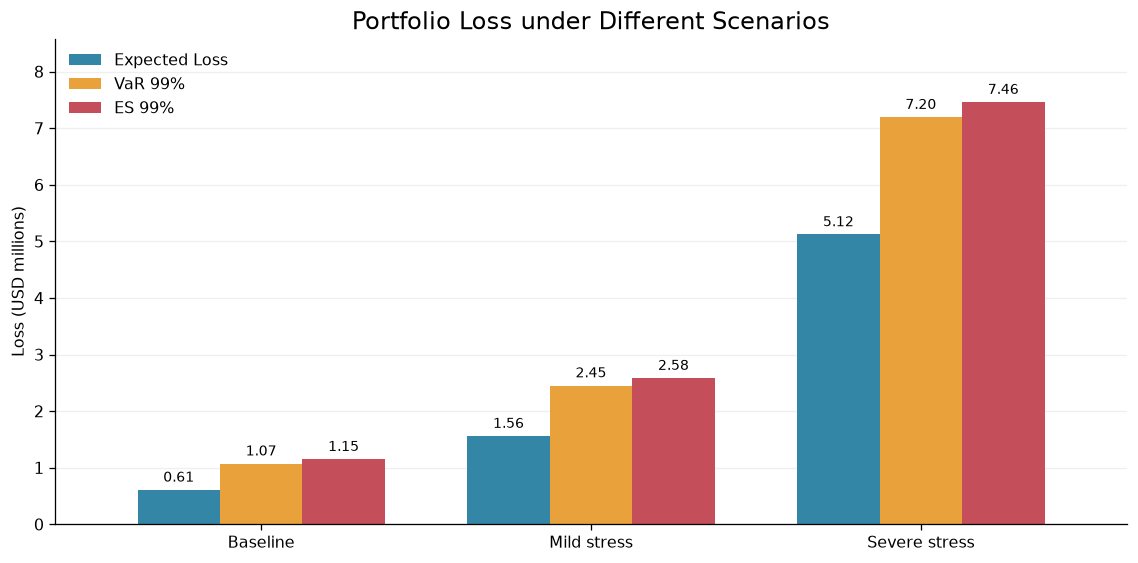

In [30]:
# Prepare the three loss measures in USD millions
chart_data = results[
    ["analytic_el_usd", "var99_usd", "es99_usd"]
].copy() / 1_000_000

chart_data.columns = [
    "Expected Loss",
    "VaR 99%",
    "ES 99%"
]

# Draw three bars for each scenario
ax = chart_data.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#3486A6", "#E9A23B", "#C44E5A"],
    width=0.75,
    rot=0
)

# Add titles and labels
ax.set_title("Portfolio Loss under Different Scenarios", fontsize=15)
ax.set_xlabel("")
ax.set_ylabel("Loss (USD millions)")
ax.legend(title="", frameon=False)

# Simplify the chart borders and add reference lines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, alpha=0.2)
ax.set_axisbelow(True)

# Display the value above each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.margins(y=0.15)
plt.tight_layout()
plt.show()

### Step 9 — Analyse expected losses by LTV band

Group loans by original LTV and compare their exposure,
expected loss and expected loss rate under severe stress.

,number_of_loans,total_exposure,expected_loss,expected_loss_rate
ltv_band,,,,
<=60%,911,230119000.0,338124.99,0.15
60-80%,1623,599410000.0,1806242.29,0.30
80-90%,504,210591000.0,984251.97,0.47
>90%,1012,366773000.0,1993894.76,0.54


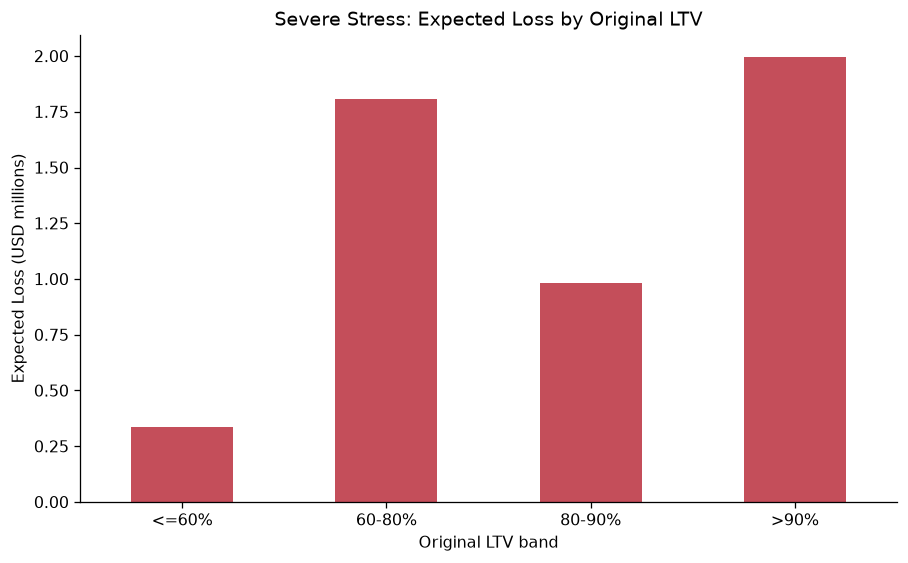

In [31]:
# Use expected losses from the severe stress scenario
portfolio["severe_expected_loss"] = (
    scenario_inputs["Severe stress"]["el"]
)

# Summarise exposure and expected loss by LTV band
ltv_summary = portfolio.groupby(
    "ltv_band", observed=True
).agg(
    number_of_loans=("loan_id", "count"),
    total_exposure=("ead", "sum"),
    expected_loss=("severe_expected_loss", "sum")
)

# Calculate expected loss as a percentage of exposure
ltv_summary["expected_loss_rate"] = (
    ltv_summary["expected_loss"]
    / ltv_summary["total_exposure"]
    * 100
)

display(ltv_summary.round(2))

# Plot expected loss contributions in USD millions
ax = (ltv_summary["expected_loss"] / 1_000_000).plot(
    kind="bar",
    figsize=(8, 5),
    color="#C44E5A",
    rot=0
)

ax.set_title("Severe Stress: Expected Loss by Original LTV")
ax.set_xlabel("Original LTV band")
ax.set_ylabel("Expected Loss (USD millions)")

plt.tight_layout()
plt.show()

### Step 10: Short findings note


In [33]:
# Identify the LTV band with the largest expected loss
top_band = ltv_summary["expected_loss"].idxmax()

# Generate a short findings note
findings = f"""
Key Findings

1. The stress portfolio contains {len(portfolio):,} loans,
   with total exposure of USD {portfolio["ead"].sum():,.0f}.

2. Expected loss increases from
   USD {results.loc["Baseline", "analytic_el_usd"]:,.0f} under baseline to
   USD {results.loc["Severe stress", "analytic_el_usd"]:,.0f} under severe stress.

3. Under severe stress, VaR 99% is
   USD {results.loc["Severe stress", "var99_usd"]:,.0f},
   while ES 99% is USD {results.loc["Severe stress", "es99_usd"]:,.0f}.

4. The original LTV band {top_band} contributes the largest
   expected loss under severe stress.

Limitations:
PD uses the historical event rate of earlier eligible cohorts.
LGD and stress shocks are illustrative assumptions.
Defaults are simulated independently, and exposure is held constant.
Results apply to the selected portfolio, not all loans in the source data.
"""

print(findings)


Key Findings

1. The stress portfolio contains 4,050 loans,
   with total exposure of USD 1,406,893,000.

2. Expected loss increases from
   USD 609,259 under baseline to
   USD 5,122,514 under severe stress.

3. Under severe stress, VaR 99% is
   USD 7,195,730,
   while ES 99% is USD 7,461,465.

4. The original LTV band >90% contributes the largest
   expected loss under severe stress.

Limitations:
PD uses the historical event rate of earlier eligible cohorts.
LGD and stress shocks are illustrative assumptions.
Defaults are simulated independently, and exposure is held constant.
Results apply to the selected portfolio, not all loans in the source data.

